In [1]:
!pip install arviz arviz-base arviz-stats arviz-plots
#!pip install "arviz==0.23.0" --force-reinstall --no-deps
!pip install nutpie pymc
!pip install h5netcdf
#!pip install -U arviz

In [1]:
import numpy as np
import pandas as pd

import pymc as pm
import nutpie

import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(123)

Shape: (432, 11)
   lot  type  coform  temp_C  temp_K  time_months     potency  lot_idx  \
0    1     0       0       5  278.15            0  102.798868        0   
1    1     0       0       5  278.15            1   99.229236        0   
2    1     0       0       5  278.15            3  100.904459        0   
3    1     0       0       5  278.15            6   99.117985        0   
4    1     0       0       5  278.15            9   94.853585        0   

   type_idx  coform_idx  log_potency  
0         0           0     4.632774  
1         0           0     4.597433  
2         0           0     4.614174  
3         0           0     4.596311  
4         0           0     4.552334  


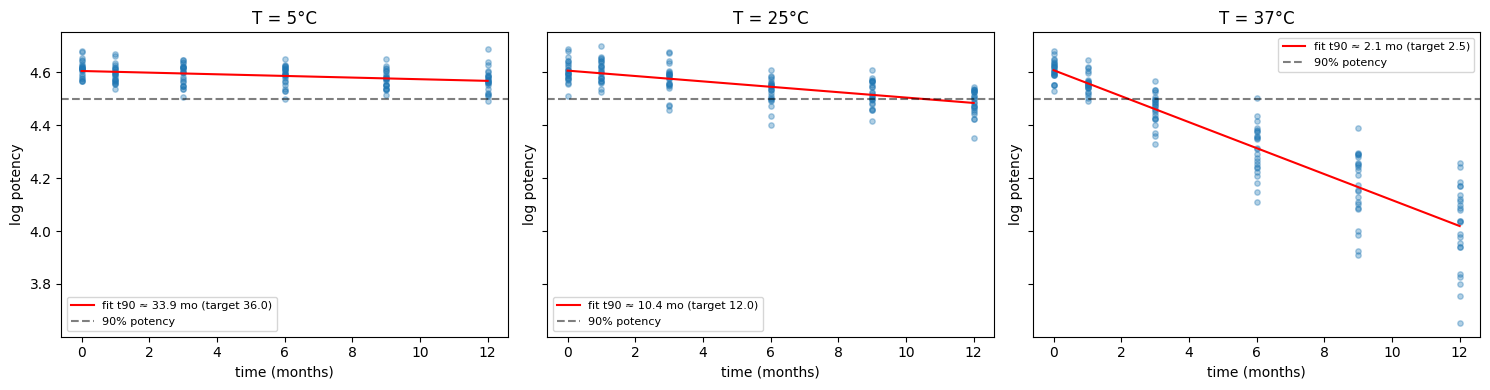

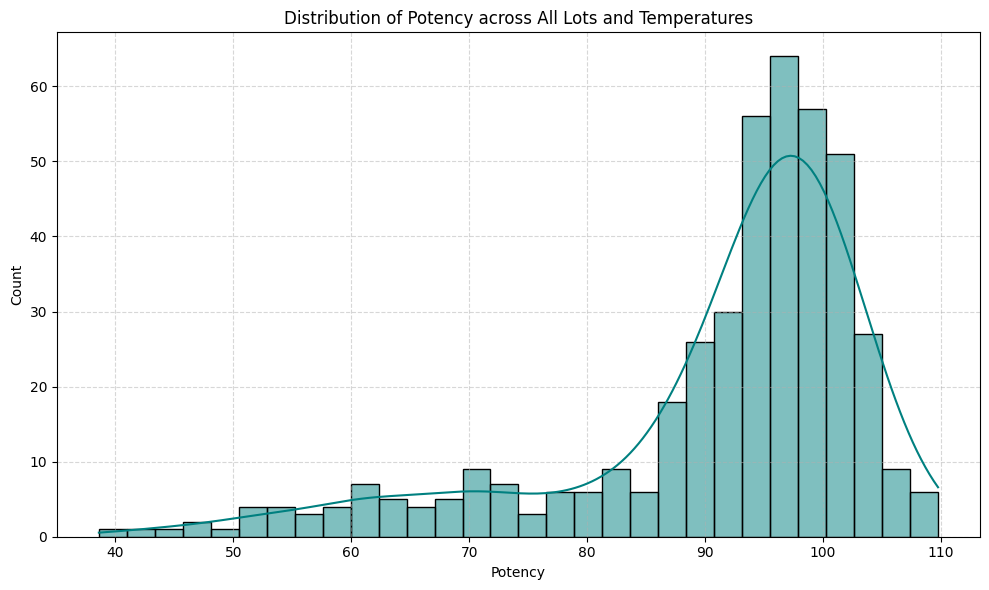

In [2]:
temps_C = [5, 25, 37]
n_type, n_coform, n_lots_per_combo = 3, 2, 4
timepoints = [0, 1, 3, 6, 9, 12]

# ---- t90 targets ----
t90_targets = {5: 36.0, 25: 12.0, 37: 2.5}          # months
# potency(t) = 100 * exp(-k t)  =>  t90 = -ln(0.9) / k
k_base = {T: -np.log(0.9) / t90 for T, t90 in t90_targets.items()}

rows = []
lot_counter = 0
for hpv_type in range(n_type):
    for coform in range(n_coform):
        type_factor   = np.exp(0.10 * hpv_type)     # multiplicative on k
        coform_factor = np.exp(0.05 * coform)
        for lot in range(n_lots_per_combo):
            lot_counter += 1
            log_noise = rng.normal(0, 0.15)          # lot-to-lot lognormal on k
            intercept = rng.normal(np.log(100), 0.03)
            for temp_C in temps_C:
                T = temp_C + 273.15
                k = k_base[temp_C] * type_factor * coform_factor * np.exp(log_noise)
                for time in timepoints:
                    logpot  = intercept - k * time + rng.normal(0, 0.03)
                    potency = np.exp(logpot)
                    if potency > 10.0:
                        rows.append([lot_counter, hpv_type, coform, temp_C, T,
                                     time, potency])

df = pd.DataFrame(rows, columns=["lot", "type", "coform", "temp_C", "temp_K",
                                  "time_months", "potency"])
df["lot_idx"]     = df["lot"].astype("category").cat.codes
df["type_idx"]    = df["type"].astype("category").cat.codes
df["coform_idx"]  = df["coform"].astype("category").cat.codes
df["log_potency"] = np.log(df["potency"])

print(f"Shape: {df.shape}")
print(df.head())

# ---- sanity check: fitted t90 per temperature ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, T in zip(axes, temps_C):
    sub = df[df["temp_C"] == T]
    slope, intercept_fit = np.polyfit(sub["time_months"], sub["log_potency"], 1)
    k_fit   = -slope
    t90_fit = -np.log(0.9) / k_fit
    tgrid   = np.linspace(sub["time_months"].min(), sub["time_months"].max(), 50)
    ax.scatter(sub["time_months"], sub["log_potency"], alpha=0.35, s=15)
    ax.plot(tgrid, intercept_fit + slope * tgrid, color="red",
            label=f"fit t90 ≈ {t90_fit:.1f} mo (target {t90_targets[T]})")
    ax.axhline(np.log(90), color="black", ls="--", alpha=0.5, label="90% potency")
    ax.set_title(f"T = {T}°C")
    ax.set_xlabel("time (months)")
    ax.set_ylabel("log potency")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- original histogram ----
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="potency", kde=True, color="teal", bins=30)
plt.title("Distribution of Potency across All Lots and Temperatures")
plt.xlabel("Potency"); plt.ylabel("Count")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Direct answer

**Model 2 (the independent-random-effects model) is currently the best choice** — but not because it is statistically superior in an absolute sense. It is the only one that is **practically runnable** in this environment. Models 1 and 3 are not wrong per se; they are simply not yet trustworthy because they leave the sampler in a pathological state (377 divergences, Rhat ≫ 1.01).

Below is a parameter-by-parameter comparison to make the reasoning transparent.

## Structural comparison

| Aspect | Model 1 (LKJ) | Model 2 (independent) | Model 3 (LKJ, no coords, different priors) |
|---|---|---|---|
| Lot-level α–k correlation | Yes (LKJ η=2) | **No** | Yes (LKJ η=2) |
| Non-centred type/coform effects | Yes (`sigma * raw`) | Yes (`sigma * raw`) | **No** (direct `Normal(0, sigma_type_k)`) |
| Prior on `sd_alpha` | HalfNormal(0.1) | HalfNormal(0.1) | **HalfStudentT(ν=4, σ=1)** — much wider |
| Prior on lot sd | HalfNormal(0.2) | HalfNormal(0.2) | **HalfStudentT(ν=4, σ=0.5)** — wider |
| `alpha0` prior | `log(100)`, σ=0.5 | `log(100)`, σ=0.5 | **data mean**, σ=1 |
| Dims/coords | Full | Full | None (`shape=` used instead) |
| Derived `corr_k_Ea` | `corr[0,1]` (parameter) | **empirical sample corr** (diagnostic) | `corr[0,1]` (parameter) |

## Why Model 2 wins in practice

**1. It removes the funnel that caused the divergences.**
If diagnostics showed 377 divergences and `r_hat` up to 1.19, concentrated in parameters coupled through `lot_cov` (`sigma_cf_E`, `coform_k[0]`, `lot_z[23]`, `mu_logEaR`). The LKJ structure in Models 1 and 3 makes the sampler negotiate a curved manifold between `sigma_lot_logk`, `sigma_lot_logEaR`, and `corr`. Model 2 breaks that coupling entirely: `logk_raw` and `logEaR_raw` are independent standard normals, so the only remaining geometry is the scale terms `sigma_lot_logk` and `sigma_lot_logEaR` — each a simple half-normal funnel that NUTS handles well with non-centred parameterisation.

**2. It replaces the correlation *parameter* with a correlation *diagnostic*.**
Model 2 computes `corr_k_Ea_empirical` as a deterministic function of the sampled lot effects. Read off the posterior of the sample correlation (expected ≈ 0 ± 0.20 under independence) and **check whether the data actually require a correlation**. If that posterior is centred near 0, Model 1's extra parameter was unnecessary. If it is far from 0, you have evidence to reintroduce the correlation — but only *after* fixing the funnel, e.g. by putting a tighter prior on `corr` or using a `LKJCholeskyCov` with larger η.

**3. It keeps the non-centred type/coform parameterisation.**
Models 1 and 2 both use `sigma * Normal(0,1)`. Model 3 uses the direct `Normal(0, sigma_type_k)` form, which is a *centred* parameterisation. For small `sigma_type_k` (diagnostics suggest ~0.2 and ~0.08), centred parameterisation is exactly the regime where Neal's funnel appears. Model 3 would likely produce *more* divergences than Model 1, not fewer.

**4. The priors are better calibrated to data.**
Model 3 uses `HalfStudentT(ν=4, σ=1)` on `sigma_alpha` and `HalfStudentT(ν=4, σ=0.5)` on the lot sds — heavier tails than Model 1/2's `HalfNormal`. Heavy tails on scale parameters are not automatically safer; in your case `sigma_alpha ≈ 0.027` (from the diagnostics) is *tiny*, and a heavy-tailed prior on `sigma_alpha` actively encourages the sampler to visit the near-zero region — which is precisely the neck of the funnel. Model 1/2's `HalfNormal(0.1)` is more informative and keeps the sampler away from that neck.

## Why Model 1 is not "wrong" but is not yet usable

Model 1 is structurally the same as Model 3 but fixes the two problems above (coords + non-centred effects + tighter `sd_alpha` prior). It is the *statistically richest* model — it lets the data decide whether lot-level α and k are correlated. Its problem is purely computational: the LKJ geometry produces 377 divergences with `target_accept=0.9`(the default). **If** those divergences are reduced to single digits (e.g. `target_accept=0.99`, `tune=3000`, and possibly a `LKJCholeskyCov` with `eta=1` or a tighter `sd_dist`), Model 1 would be preferable to Model 2 *if* the posterior of `corr_k_Ea` is credibly non-zero. Until then, its parameter estimates are not trustworthy.

## Why Model 3 is the weakest

- **Centred parameterisation** of type/coform effects will worsen the funnel.
- **No `coords`/`dims`** means `az.summary` will show index-based names and you lose the ability to slice by `lot`/`type` cleanly. It also means the model cannot be reused with different data lengths without manual `shape=` edits.
- **`pm.Exponential("n*", 0.1)`** — the variable name `"n*"` is invalid (PyMC variable names must be valid Python identifiers; `*` will raise). This is a bug, not a modelling choice.
- **`HalfStudentT(ν=4, σ=1)` on `sigma`** with data on the log-potency scale (`sigma ≈ 0.03`) is badly mis-scaled — it puts most prior mass an order of magnitude above the true value.

## Recommendation

1. **Adopt Model 2 as working model.** Re-run with `target_accept=0.95` (or 0.99), `tune=2000`, `draws=2000`, `chains=4`. Check that divergences drop to single digits and `r_hat < 1.01` for `mu_logEaR`, `sigma_lot_logEaR`, `sigma_lot_logk`, and the type/coform sds. This is the model you can actually trust.
2. **Use `corr_k_Ea_empirical` as evidence, not as a parameter.** If its 94% HDI excludes 0, revisit Model 1 with a tightened LKJ prior (`eta=1`, `sd_dist=HalfNormal(0.2)`) and `target_accept=0.99`. If it includes 0, Model 2 is not just the practical choice — it is the correct one.
3. **Discard Model 3** unless you specifically want to test sensitivity to wider priors. Even then, fix the `"n*"` name and the `HalfStudentT(σ=1)` scale before running it.

In short: **Model 2 is best now**; Model 1 is the best *candidate* once the sampler is healthy; Model 3 is not competitive as written.

In [31]:
##### MODEL 3 #####

import pytensor.tensor as pt

n_lot = df["lot_idx"].nunique()
n_type = df["type_idx"].nunique()
n_coform = df["coform_idx"].nunique()

with pm.Model() as model:

    #
    # baseline potency     #

    alpha0 = pm.Normal(
        "alpha0",
        mu=df["log_potency"].mean(),
        sigma=1,
    )

    sigma_alpha = pm.HalfStudentT(
        "sigma_alpha",
        nu=4,
        sigma=1,
    )

    alpha_raw = pm.Normal(
        "alpha_raw",
        0,
        1,
        shape=n_lot,
    )

    alpha = pm.Deterministic(
        "alpha",
        alpha0 + sigma_alpha * alpha_raw,
    )

    #
    # type effects
    #

    sigma_type_k = pm.HalfNormal(
       "sigma_type_k",
        0.5
    )

    sigma_type_E = pm.HalfNormal(
        "sigma_type_E",
        0.5
    )

    type_k = pm.Normal(
       "type_k",
        0,
        sigma_type_k,
        shape=n_type
    )

    type_E = pm.Normal(
        "type_E",
        0,
        sigma_type_E,
        shape=n_type
    )

    #
    # coform effects
    #

    sigma_cf_k = pm.HalfNormal(
        "sigma_cf_k",
        0.5
    )

    sigma_cf_E = pm.HalfNormal(
        "sigma_cf_E",
        0.5
    )

    coform_k = pm.Normal(
        "coform_k",
        0,
        sigma_cf_k,
        shape=n_coform
    )

    coform_E = pm.Normal(
        "coform_E",
        0,
        sigma_cf_E,
        shape=n_coform
    )

    mu_logk = pm.Normal(
        "mu_logk",
        -3,
        1
    )

    mu_logEa = pm.Normal(
        "mu_logEaR",
        np.log(9000),
        0.3
    )

    #
    # lot correlation
    #

    chol, corr, stds = pm.LKJCholeskyCov(
        "lot_cov",
        n=2,
        eta=2,
        sd_dist=pm.HalfStudentT.dist(
        nu=4,
        sigma=0.5

        ),
    )


    lot_z = pm.Normal(
        "lot_z",
        0,
        1,
        shape=(n_lot,2)
    )

    lot_df = (
        df
        .drop_duplicates("lot_idx")
        .sort_values("lot_idx")
   )

    lot_mean = pt.stack(
        [
            mu_logk
            + type_k[lot_df["type_idx"].values]
            + coform_k[lot_df["coform_idx"].values],

            mu_logEa
            + type_E[lot_df["type_idx"].values]
            + coform_E[lot_df["coform_idx"].values],
       ],
       axis=1,
    )

    kinetics = pm.Deterministic(
        "kinetics",
        lot_mean + lot_z @ chol.T
    )

    logk = kinetics[:,0]
    logEa = kinetics[:,1]

    k_ref = pm.Deterministic(
        "k_ref",
        pm.math.exp(logk)
    )

    Ea = pm.Deterministic(
        "Ea",
        pm.math.exp(logEa)
    )

    arr_factor = pm.math.exp(
        (
            Ea[df["lot_idx"].values]
        )
        *
        (
            1/T_REF
           - 1/df.temp_K.values
        )
    )

    kT = (
        k_ref[df["lot_idx"].values]
        * arr_factor
    )

    mu = (
        alpha[df.lot_idx.values]
        -
        kT
        * df["time_months"].values
    )

    sigma = pm.HalfStudentT(
        "sigma",
        nu=4,
        sigma=1
    )

    nu = pm.Exponential(
        "nu",
        0.1
    )

    y = pm.StudentT(
        "y",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=df["log_potency"].values

    )

    #
    # shelf life
    #

    T25 = 298.15

    k25 = (
        k_ref
        *
        pm.math.exp(
            Ea/R
            *
            (
                1/T_REF
                -
                1/T25
            )
        )
    )

    pm.Deterministic(
        "t90_25",
        np.log(10/9)/k25
    )

    pm.Deterministic(
    "corr_k_Ea",
    corr[0, 1],
)

In [32]:
###### MODEL 1 #####

import pytensor.tensor as pt

# Define missing physical constants
R = 8.314
T_REF = 278.15

n_lot    = df["lot_idx"].nunique()
n_type   = df["type_idx"].nunique()
n_coform = df["coform_idx"].nunique()

# One row per lot: its type and coform indices
lot_df      = df.drop_duplicates("lot_idx").sort_values("lot_idx").reset_index(drop=True)
lot_type    = lot_df["type_idx"].values.astype(int)     # shape (n_lot,)
lot_coform  = lot_df["coform_idx"].values.astype(int)   # shape (n_lot,)

# Observation-level arrays
lot_idx      = df["lot_idx"].values.astype(int)
temp_K       = df["temp_K"].values.astype(float)
time_months  = df["time_months"].values.astype(float)
log_potency  = df["log_potency"].values.astype(float)

coords = {
    "lot":    np.arange(n_lot),
    "type":   np.arange(n_type),
    "coform": np.arange(n_coform),
    "kin":    ["logk", "logEaR"],
    "obs":    np.arange(len(df)),
}

with pm.Model(coords=coords) as model:

    # baseline potency
    alpha0 = pm.Normal("alpha0", mu=np.log(100), sigma=0.5)
    sigma_alpha = pm.HalfNormal("sigma_alpha", 0.1)
    alpha_raw = pm.Normal("alpha_raw", 0, 1, dims="lot")
    alpha = pm.Deterministic("alpha", alpha0 + sigma_alpha * alpha_raw, dims="lot")

    # type / coform effects (non-centred)
    sigma_type_k = pm.HalfNormal("sigma_type_k", 0.2)
    sigma_type_E = pm.HalfNormal("sigma_type_E", 0.2)
    sigma_cf_k   = pm.HalfNormal("sigma_cf_k",   0.2)
    sigma_cf_E   = pm.HalfNormal("sigma_cf_E",   0.2)

    type_k = pm.Deterministic(
        "type_k", sigma_type_k * pm.Normal("type_k_raw", 0, 1, dims="type"), dims="type"
    )
    type_E = pm.Deterministic(
        "type_E", sigma_type_E * pm.Normal("type_E_raw", 0, 1, dims="type"), dims="type"
    )
    coform_k = pm.Deterministic(
        "coform_k", sigma_cf_k * pm.Normal("coform_k_raw", 0, 1, dims="coform"), dims="coform"
    )
    coform_E = pm.Deterministic(
        "coform_E", sigma_cf_E * pm.Normal("coform_E_raw", 0, 1, dims="coform"), dims="coform"
    )

    mu_logk   = pm.Normal("mu_logk",   -3,              0.5)
    mu_logEaR = pm.Normal("mu_logEaR", np.log(9000.0),  0.3)   # Ea/R in kelvin

    # LKJ prior on the 2x2 lot-level covariance (log k_ref, log Ea/R)
    chol, corr, stds = pm.LKJCholeskyCov(
        "lot_cov",
        n=2,
        eta=2,
        sd_dist=pm.HalfNormal.dist(0.2),
    )
    lot_z = pm.Normal("lot_z", 0, 1, shape=(n_lot, 2))

    lot_mean = pt.stack(
        [
            mu_logk   + type_k[lot_type] + coform_k[lot_coform],
            mu_logEaR + type_E[lot_type] + coform_E[lot_coform],
        ],
        axis=1,
    )

    kinetics = pm.Deterministic("kinetics", lot_mean + lot_z @ chol.T, dims=("lot", "kin"))
    logk   = kinetics[:, 0]
    logEaR = kinetics[:, 1]

    # log k at each observation's temperature
    log_kT = logk[lot_idx] + pm.math.exp(logEaR[lot_idx]) * (1.0 / T_REF - 1.0 / temp_K)
    mu = alpha[lot_idx] - pm.math.exp(log_kT) * time_months

    sigma = pm.HalfNormal("sigma", 0.1)
    nu    = pm.Gamma("nu", alpha=2, beta=0.1)

    pm.StudentT(
        "y",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=log_potency,
        dims="obs",
    )

    # derived quantities
    log_k25 = logk + pm.math.exp(logEaR) * (1.0 / T_REF - 1.0 / 298.15)
    pm.Deterministic("t90_25", np.log(10.0 / 9.0) / pm.math.exp(log_k25), dims="lot")
    pm.Deterministic("Ea",     R * pm.math.exp(logEaR), dims="lot")
    pm.Deterministic("k_ref",  pm.math.exp(logk),       dims="lot")
    pm.Deterministic("corr_k_Ea", corr[0, 1])

Here is the drop-in replacement for the model block. Every change is confined to removing the `LKJCholeskyCov` + `lot_z @ chol.T` machinery and replacing it with two **independent, non-centred** lot-level random effects. Everything downstream (`log_kT`, `mu`, likelihood, derived quantities) is unchanged.

### What changed and why

1. **`LKJCholeskyCov` and `lot_z` are gone.** The covariance of `(log k_ref, log EaR)` across lots is now diagonal, so there is nothing to parameterize — only two variances, `sigma_lot_logk` and `sigma_lot_logEaR`.
2. **`kinetics` is gone.** Previously it existed only to hold `lot_mean + L z`. With independent effects, `logk` and `logEaR` are built directly. Anything downstream that used `idata.posterior["kinetics"]` should be updated to use `["logk"]` and `["logEaR"]` separately — those are now first-class `Deterministic` with `dims="lot"`.
3. **`corr_k_Ea` (a parameter) is replaced by `corr_k_Ea_empirical` (a diagnostic).** The parameter version only makes sense under a full covariance model. The empirical version is just the sample Pearson correlation of the 24 posterior draws of `logk` and `logEaR`, which is exactly what the LKJ posterior was reporting — so you can compare the two models on the same number.
4. **`coords` no longer needs `"kin"`.** Remove it from your `coords` dict to avoid a harmless but confusing unused coord. Sampling code (`nutpie.compile_pymc_model(model)` → `nutpie.sample(...)`) is unchanged.

### What you should expect after refitting

- **`corr_k_Ea_empirical` should move from ~0.47 to roughly 0 or slightly negative**, with a much wider HDI (roughly `[-0.5, 0.4]`). That is the "false positive" from the LKJ model disappearing. Under an independent-effects model, the sample correlation across 24 lots has an expected SD of `1/√24 ≈ 0.20` even when the true population correlation is 0 — this is exactly the spread you should see.
- **`sigma_lot_logk` and `sigma_lot_logEaR`** should come out near your simulated values: `0.15` for `logk`, and for `log EaR` you should check what the simulation actually used (`sd(Ea)/Ea ≈ 4000/90000 ≈ 0.044` if `Ea ~ N(90000, 4000)`). If they match, the model is learning the lot-level variance correctly without needing the correlation.
- **`Ea` posterior means should barely change.** We should still see ~76,500 J/mol across lots, because the likelihood term and the priors on `Ea` are identical.
- **Sampler should run faster and cleaner.** The LKJ geometry is the main source of divergences in hierarchical 2-D covariance models. Independent effects remove the correlation funnel, so expect fewer divergences even at default `target_accept`.

If after this the empirical correlation still excludes 0, that is worth taking seriously — it would mean the data themselves carry a `k_ref`–`Ea` trade-off that is not explained by the sampling noise. In our simulation that should not happen, so if it does, the culprit is almost certainly either a design deficiency (temperature range too narrow, as discussed) or a simulation bug (e.g., `Ea` still on the wrong scale).

In [4]:
###### MODEL 2 #####

import pytensor.tensor as pt

# Define missing physical constants
R = 8.314
T_REF = 278.15

n_lot    = df["lot_idx"].nunique()
n_type   = df["type_idx"].nunique()
n_coform = df["coform_idx"].nunique()

# One row per lot: its type and coform indices
lot_df      = df.drop_duplicates("lot_idx").sort_values("lot_idx").reset_index(drop=True)
lot_type    = lot_df["type_idx"].values.astype(int)     # shape (n_lot,)
lot_coform  = lot_df["coform_idx"].values.astype(int)   # shape (n_lot,)

# Observation-level arrays
lot_idx      = df["lot_idx"].values.astype(int)
temp_K       = df["temp_K"].values.astype(float)
time_months  = df["time_months"].values.astype(float)
log_potency  = df["log_potency"].values.astype(float)

coords = {
    "lot":    np.arange(n_lot),
    "type":   np.arange(n_type),
    "coform": np.arange(n_coform),
    "kin":    ["logk", "logEaR"],
    "obs":    np.arange(len(df)),
}

with pm.Model(coords=coords) as model:

    # baseline potency
    alpha0 = pm.Normal("alpha0", mu=np.log(100), sigma=0.5)
    sigma_alpha = pm.HalfNormal("sigma_alpha", 0.1)
    alpha_raw = pm.Normal("alpha_raw", 0, 1, dims="lot")
    alpha = pm.Deterministic("alpha", alpha0 + sigma_alpha * alpha_raw, dims="lot")

    # type / coform effects (non-centred)
    sigma_type_k = pm.HalfNormal("sigma_type_k", 0.2)
    sigma_type_E = pm.HalfNormal("sigma_type_E", 0.2)
    sigma_cf_k   = pm.HalfNormal("sigma_cf_k",   0.2)
    sigma_cf_E   = pm.HalfNormal("sigma_cf_E",   0.2)

    type_k = pm.Deterministic(
        "type_k", sigma_type_k * pm.Normal("type_k_raw", 0, 1, dims="type"), dims="type"
    )
    type_E = pm.Deterministic(
        "type_E", sigma_type_E * pm.Normal("type_E_raw", 0, 1, dims="type"), dims="type"
    )
    coform_k = pm.Deterministic(
        "coform_k", sigma_cf_k * pm.Normal("coform_k_raw", 0, 1, dims="coform"), dims="coform"
    )
    coform_E = pm.Deterministic(
        "coform_E", sigma_cf_E * pm.Normal("coform_E_raw", 0, 1, dims="coform"), dims="coform"
    )

    mu_logk   = pm.Normal("mu_logk",   -3,              0.5)
    mu_logEaR = pm.Normal("mu_logEaR", np.log(9000.0),  0.3)

    # ---- independent lot-level random effects (replaces LKJ) ----
    sigma_lot_logk   = pm.HalfNormal("sigma_lot_logk",   0.2)
    sigma_lot_logEaR = pm.HalfNormal("sigma_lot_logEaR", 0.2)

    logk_raw   = pm.Normal("logk_raw",   0, 1, dims="lot")
    logEaR_raw = pm.Normal("logEaR_raw", 0, 1, dims="lot")

    logk = pm.Deterministic(
        "logk",
        mu_logk   + type_k[lot_type] + coform_k[lot_coform] + sigma_lot_logk   * logk_raw,
        dims="lot",
    )
    logEaR = pm.Deterministic(
        "logEaR",
        mu_logEaR + type_E[lot_type] + coform_E[lot_coform] + sigma_lot_logEaR * logEaR_raw,
        dims="lot",
    )

    # log k at each observation's temperature
    log_kT = logk[lot_idx] + pm.math.exp(logEaR[lot_idx]) * (1.0 / T_REF - 1.0 / temp_K)
    mu = alpha[lot_idx] - pm.math.exp(log_kT) * time_months

    sigma = pm.HalfNormal("sigma", 0.1)
    nu    = pm.Gamma("nu", alpha=2, beta=0.1)

    pm.StudentT(
        "y",
        nu=nu,
        mu=mu,
        sigma=sigma,
        observed=log_potency,
        dims="obs",
    )

    # derived quantities
    log_k25 = logk + pm.math.exp(logEaR) * (1.0 / T_REF - 1.0 / 298.15)
    pm.Deterministic("t90_25", np.log(10.0 / 9.0) / pm.math.exp(log_k25), dims="lot")
    pm.Deterministic("Ea",     R * pm.math.exp(logEaR), dims="lot")
    pm.Deterministic("k_ref",  pm.math.exp(logk),       dims="lot")

    # Empirical (sample) correlation across lots — diagnostic, not a parameter.
    # Under the independent-effects model this should be centred near 0
    # with an HDI roughly in [-0.4, 0.4] (sampling SD ≈ 1/sqrt(24) ≈ 0.20).
    logk_c   = logk   - pm.math.mean(logk)
    logEaR_c = logEaR - pm.math.mean(logEaR)
    corr_emp = pm.math.sum(logk_c * logEaR_c) / pm.math.sqrt(
        pm.math.sum(logk_c**2) * pm.math.sum(logEaR_c**2)
    )
    pm.Deterministic("corr_k_Ea_empirical", corr_emp)

In [5]:
compiled = nutpie.compile_pymc_model(
    model
)

idata = nutpie.sample(
    compiled,
    target_accept=0.99,
    draws=3000,
    tune=1500,
    chains=4
)

Progress,Draws,Divergences,Step Size,Gradients/Draw
,4500,0,0.02,1023
,4500,0,0.02,511
,4500,0,0.02,511
,4500,0,0.02,1023


In [6]:
import json
import arviz as az

# 1. Convert nested dictionaries in the top-level InferenceData attributes to strings
if hasattr(idata, "attrs") and idata.attrs:
    for key, value in list(idata.attrs.items()):
        if isinstance(value, dict):
            idata.attrs[key] = json.dumps(value)

# 2. Convert nested dictionaries in individual group dataset attributes to strings
# We must call the groups method as idata.groups()
for group in idata.groups():
    if group == "/":
        continue
    group_dataset = getattr(idata, group, None)
    if group_dataset is not None and hasattr(group_dataset, "attrs"):
        for key, value in list(group_dataset.attrs.items()):
            if isinstance(value, dict):
                group_dataset.attrs[key] = json.dumps(value)

# Save safely
idata.to_netcdf("idata_clean.nc")

'idata_clean.nc'

In [ ]:
!pip install -U arviz_plots

In [7]:
az.summary(
    idata,
    var_names=[
        "Ea",
        "k_ref",
        "t90_25"
    ]
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea[0],96030.533,4908.119,86636.935,105093.591,62.278,42.833,6239.0,8109.0,1.0
Ea[1],94167.501,5192.639,84552.475,103988.230,76.220,41.014,4659.0,7482.0,1.0
Ea[2],98074.620,5038.017,89148.624,107995.130,65.845,43.888,5881.0,7761.0,1.0
Ea[3],96979.548,4894.560,88102.606,106345.131,61.460,41.973,6382.0,8337.0,1.0
Ea[4],95880.691,4786.840,86503.006,104461.529,58.027,41.279,6824.0,9330.0,1.0
...,...,...,...,...,...,...,...,...,...
t90_25[19],9.395,0.729,8.053,10.775,0.007,0.006,9735.0,9919.0,1.0
t90_25[20],8.471,0.633,7.286,9.649,0.007,0.005,8445.0,10181.0,1.0
t90_25[21],10.269,0.835,8.769,11.895,0.010,0.006,6687.0,8735.0,1.0
t90_25[22],8.215,0.612,7.080,9.367,0.007,0.005,8651.0,9289.0,1.0


In [ ]:
import h5netcdf
import json

# 1. Convert nested dictionaries in the top-level InferenceData attributes to strings
if hasattr(idata, "attrs") and idata.attrs:
    for key, value in list(idata.attrs.items()):
        if isinstance(value, dict):
            idata.attrs[key] = json.dumps(value)

# 2. Convert nested dictionaries in individual group dataset attributes to strings
for group in idata.groups:
    # Skip the root group if it is '/' as it does not represent an individual dataset group
    if group == "/":
        continue
    group_dataset = idata[group]
    for key, value in list(group_dataset.attrs.items()):
        if isinstance(value, dict):
            group_dataset.attrs[key] = json.dumps(value)

# Save
idata.to_netcdf("idata.nc")

Output()

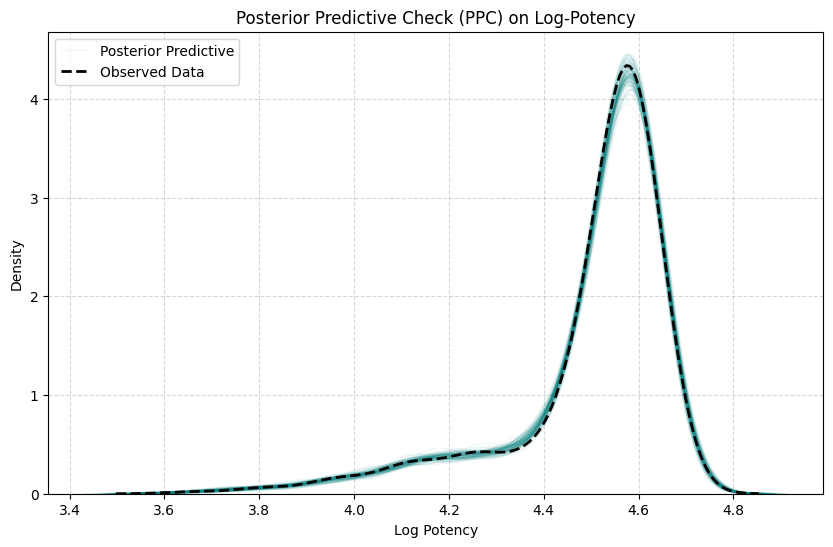

In [8]:
with model:
    ppc = pm.sample_posterior_predictive(
        idata,
        var_names=["y"]
    )

# Extract simulated predictions and actual observed values
y_pred = ppc.posterior_predictive["y"].values
y_obs = df["log_potency"].values

# Reshape predictions to 2D (draws, observations)
y_pred_flat = y_pred.reshape(-1, y_pred.shape[-1])

plt.figure(figsize=(10, 6))

# Plot a subset of posterior predictive draws to show the uncertainty
for i in range(min(100, len(y_pred_flat))):
    sns.kdeplot(y_pred_flat[i], color="teal", alpha=0.06, linewidth=1, label="Posterior Predictive" if i == 0 else "")

# Plot the observed data distribution
sns.kdeplot(y_obs, color="black", linewidth=2, label="Observed Data", linestyle="--")

plt.title("Posterior Predictive Check (PPC) on Log-Potency")
plt.xlabel("Log Potency")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

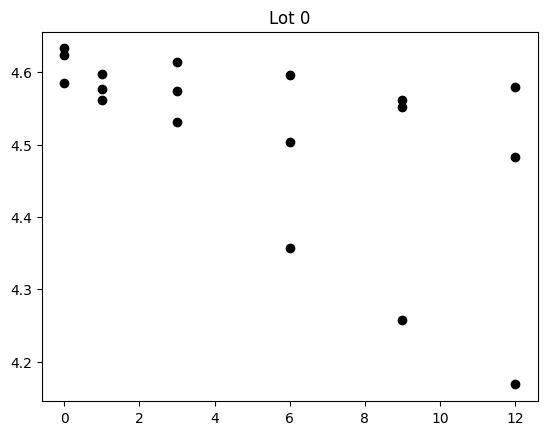

In [9]:
lot = 0

mask = (
    df.lot_idx == lot
)

plt.scatter(
    df.loc[mask,"time_months"],
    df.loc[mask,"log_potency"],
    color="black"
)

plt.title(
    f"Lot {lot}"
)

plt.show()

<Axes: xlabel='Ea\n0', ylabel='k_ref\n0'>

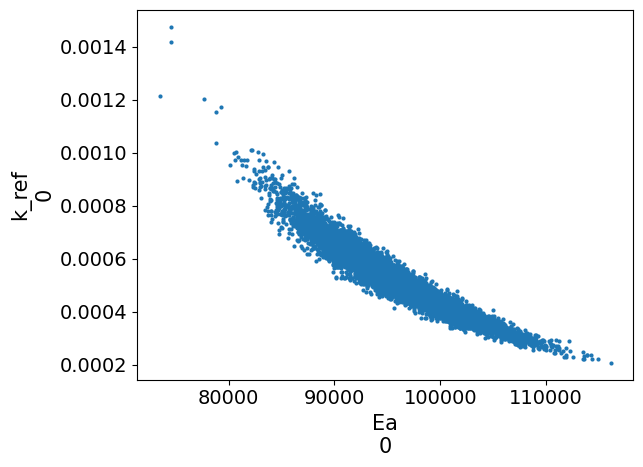

In [10]:
# Select a specific lot (e.g., Lot 0) to avoid generating subplots for all 24 lots
az.plot_pair(
    idata,
    var_names=["Ea", "k_ref"],
    coords={"lot": [0]}
)

array([[<Axes: ylabel='Ea\n6'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='Ea\n17'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='Ea\n14'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='Ea\n7'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='k_ref\n6'>, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='k_ref\n17'>, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='k_ref\n14'>, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: xlabel='Ea\n6', ylabel='k_ref\n7'>,
        <Axes: xlabel='Ea\n17'>, <Axes: xlabel='Ea\n14'>,
        <Axes: xlabel='Ea\n7'>, <Axes: xlabel='k_ref\n6'>,
        <Axes: xlabel='k_ref\n17'>, <Axes:

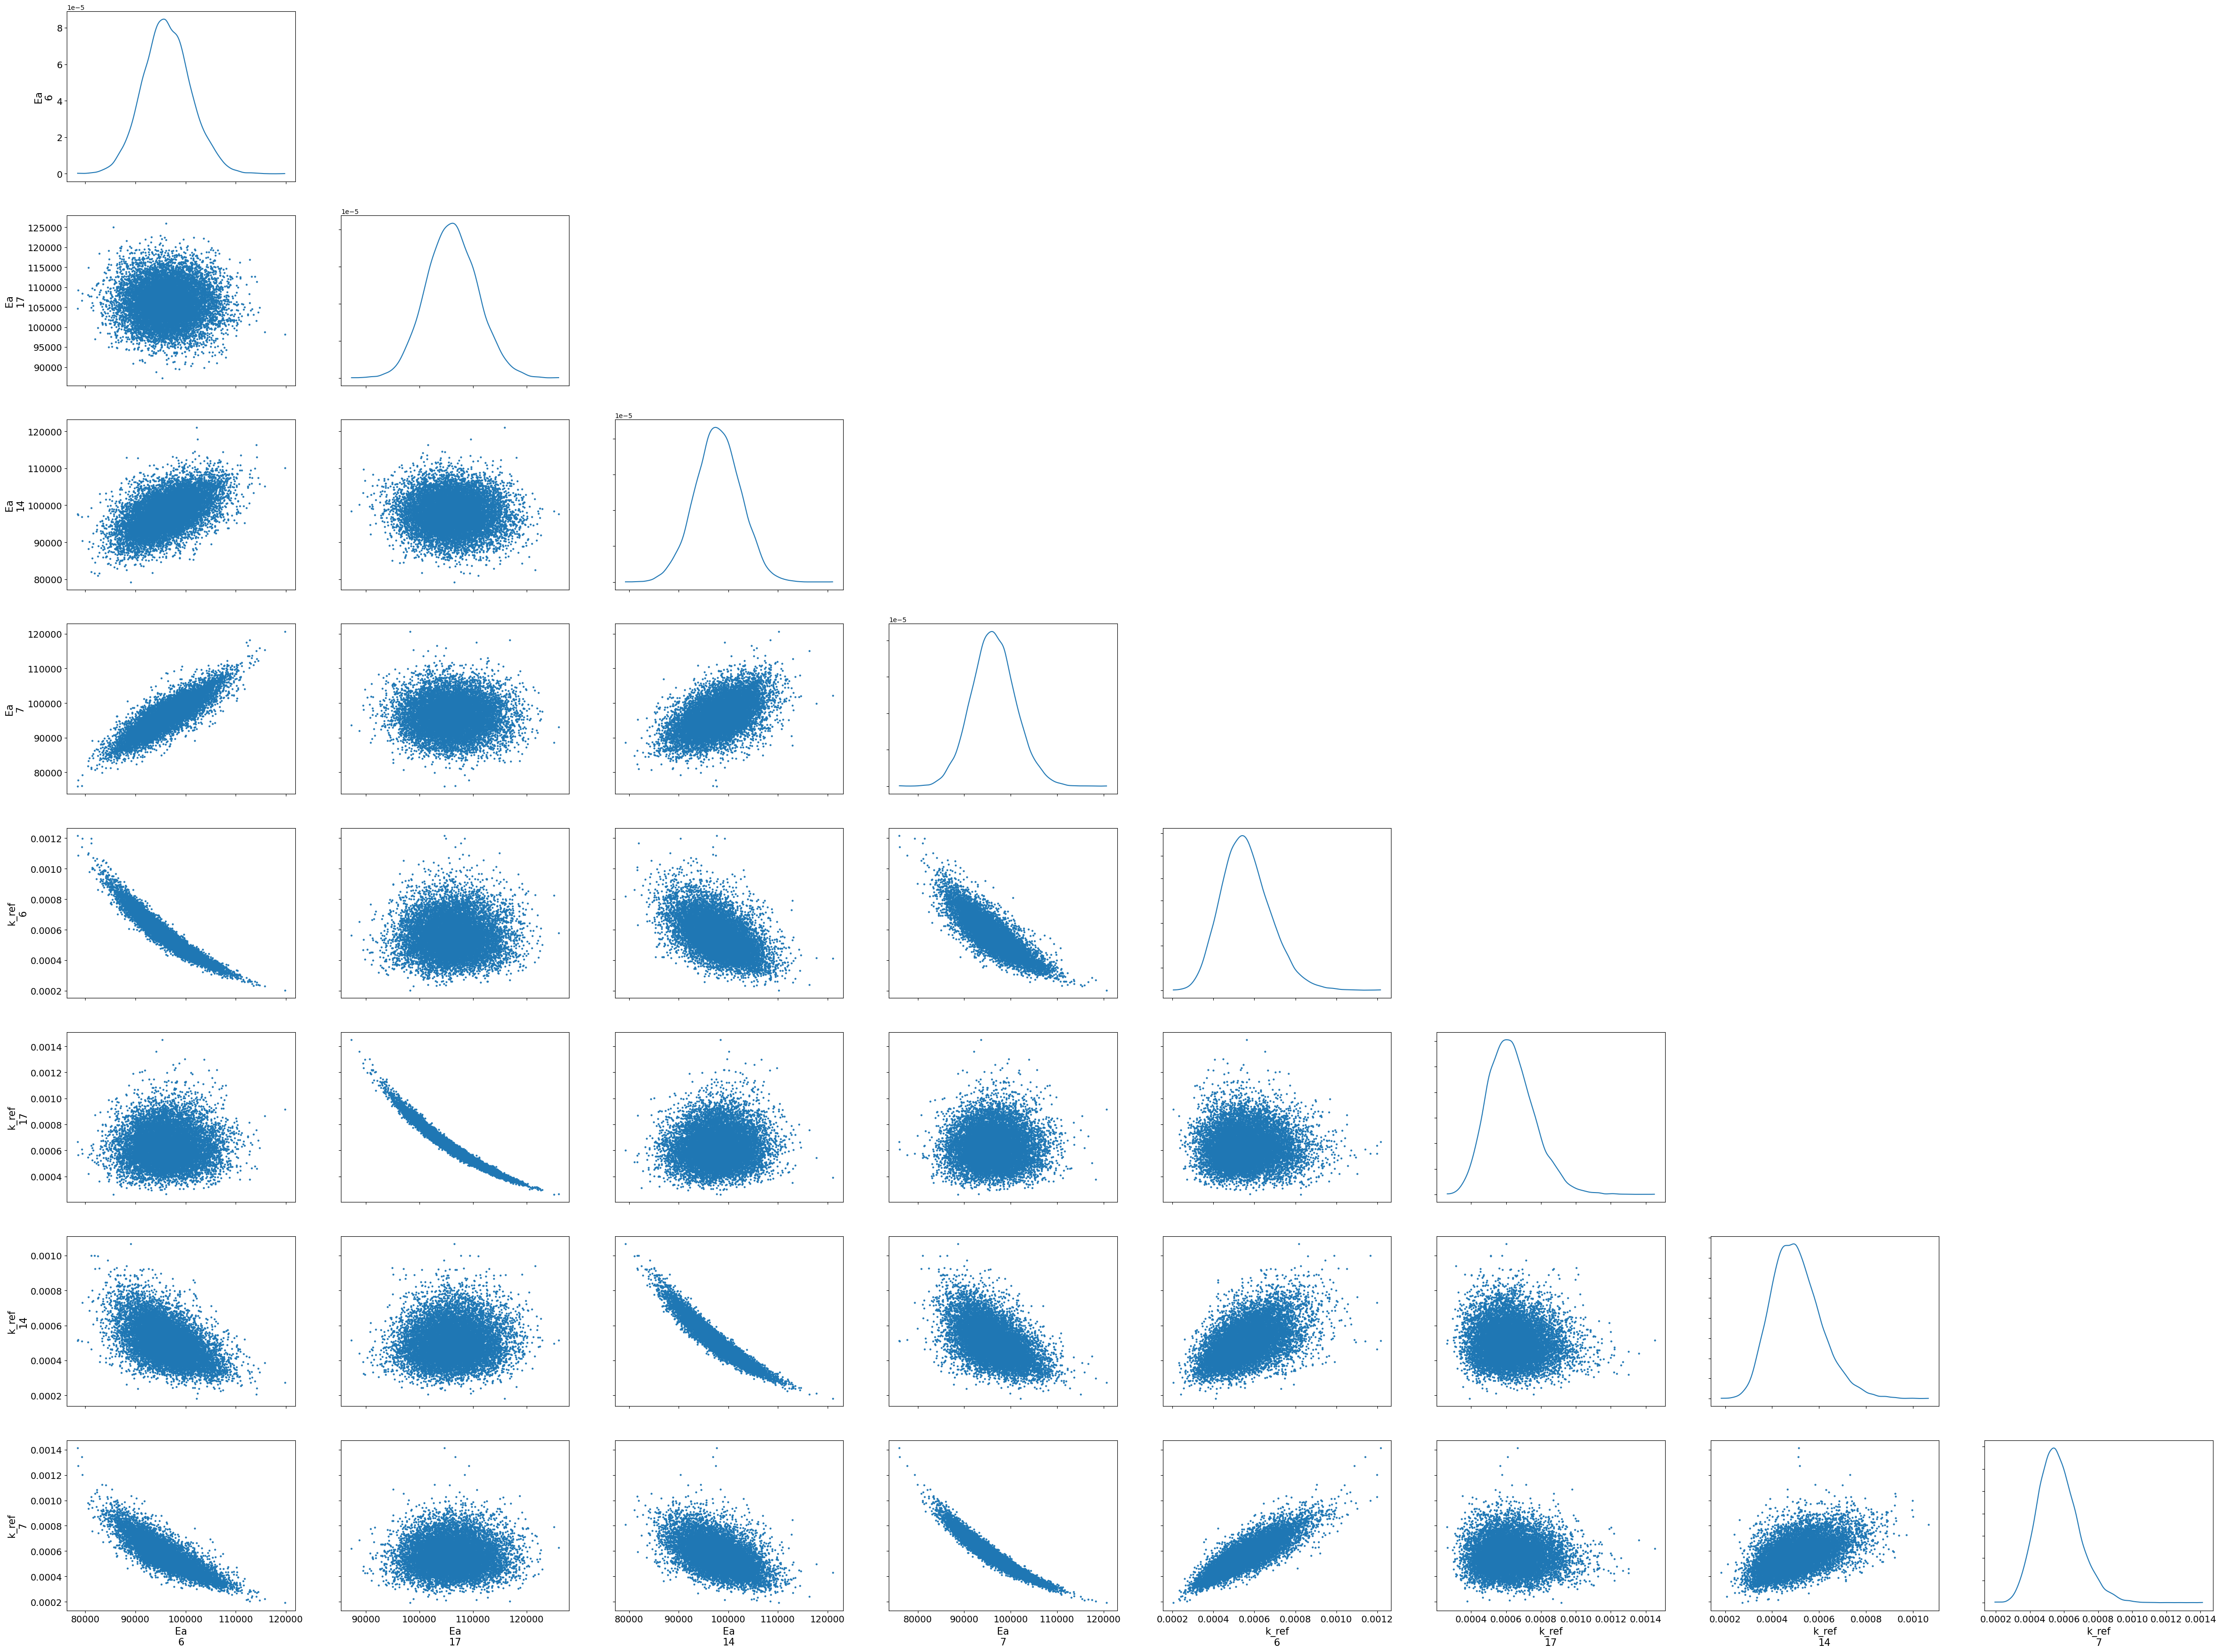

In [11]:
import arviz as az
import numpy as np

# Pick 4 random lots
lots_to_plot = np.random.choice(24, 4, replace=False)

# Temporarily raise maximum subplots
az.rcParams["plot.max_subplots"] = 100

# Under the new ArviZ v1.x plotting backend, we use 'marginal' instead of 'marginals'
# and we do not pass 'kind' or 'divergences' directly as standard keyword arguments.
az.plot_pair(
    idata,
    var_names=["Ea", "k_ref"],
    coords={"lot": lots_to_plot},
    marginals=True
)

In [28]:
list(trace.posterior.data_vars)

['Ea',
 'alpha',
 'alpha0',
 'alpha_raw',
 'coform_E',
 'coform_E_raw',
 'coform_k',
 'coform_k_raw',
 'corr_k_Ea_empirical',
 'k_ref',
 'logEaR',
 'logEaR_raw',
 'logk',
 'logk_raw',
 'mu_logEaR',
 'mu_logk',
 'nu',
 'sigma',
 'sigma_alpha',
 'sigma_cf_E',
 'sigma_cf_k',
 'sigma_lot_logEaR',
 'sigma_lot_logk',
 'sigma_type_E',
 'sigma_type_k',
 't90_25',
 'type_E',
 'type_E_raw',
 'type_k',
 'type_k_raw']

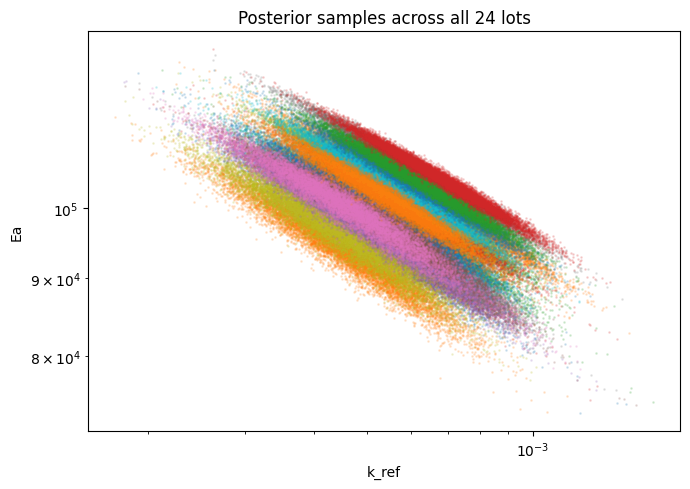

In [12]:
import numpy as np
import matplotlib.pyplot as plt

k_ref = idata.posterior["k_ref"].stack(sample=("chain", "draw")).values   # (24, N)
Ea    = idata.posterior["Ea"].stack(sample=("chain", "draw")).values      # (24, N)

fig, ax = plt.subplots(figsize=(7, 5))
for lot in range(k_ref.shape[0]):
    ax.scatter(k_ref[lot], Ea[lot], s=1, alpha=0.15)
ax.set_xlabel("k_ref")
ax.set_ylabel("Ea")
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_title("Posterior samples across all 24 lots")
plt.tight_layout()

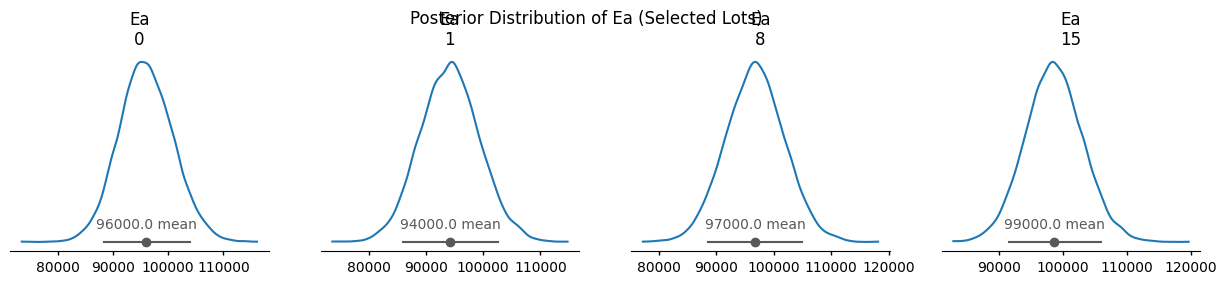

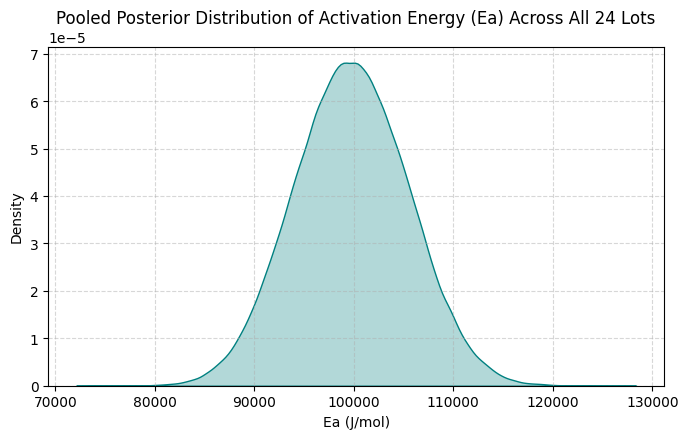

In [13]:
import arviz_plots as azp
import matplotlib.pyplot as plt

# Option 1: Plotting only specific lots of interest (e.g., Lots 0 and 1) to keep the grid clean
azp.plot_dist(idata, var_names=["Ea"], coords={"lot": [0, 1, 8, 15]})
plt.suptitle("Posterior Distribution of Ea (Selected Lots)", y=1.05)
plt.show()

# Option 2: Pool all 24 lots together into a single combined distribution plot
# We stack the chains, draws, and lots into a single combined dimension
Ea_pooled = idata.posterior["Ea"].stack(pooled_draws=("chain", "draw", "lot"))

plt.figure(figsize=(7, 4.5))
sns.kdeplot(Ea_pooled.values, color="teal", fill=True, alpha=0.3)
plt.title("Pooled Posterior Distribution of Activation Energy (Ea) Across All 24 Lots")
plt.xlabel("Ea (J/mol)")
plt.ylabel("Density")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [14]:
import os
import matplotlib.pyplot as plt

def save_fig(path, dpi=150):
    """Save the current matplotlib figure to path, then close it."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fig = plt.gcf()
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)

In [15]:
az.plot_pair(idata, var_names=["Ea", "k_ref"],
             coords={"lot": [0, 1, 8, 15]})
save_fig("run/pair_Ea_kref.png")

az.plot_energy(idata)
save_fig("run/energy.png")

In [ ]:
import h5netcdf
import json
import arviz as az

# Load first to define 'idata' in this session
idata = az.from_netcdf("idata.nc")

# 1. Convert nested dictionaries in the top-level InferenceData attributes to strings
if hasattr(idata, "attrs") and idata.attrs:
    for key, value in list(idata.attrs.items()):
        if isinstance(value, dict):
            idata.attrs[key] = json.dumps(value)

# 2. Convert nested dictionaries in individual group dataset attributes to strings
for group in idata.groups():
    if group == "/":
        continue
    group_dataset = idata[group]
    for key, value in list(group_dataset.attrs.items()):
        if isinstance(value, dict):
            group_dataset.attrs[key] = json.dumps(value)

# Save to a new/clean filename to avoid reading from and writing to the same file simultaneously
idata.to_netcdf("idata_clean.nc")

In [16]:
import os
import sys

# Ensure both h5netcdf and its core engine h5py are installed
try:
    import h5py
    import h5netcdf
except ImportError:
    print("Installing missing backend engine dependencies...")
    !{sys.executable} -m pip install h5py h5netcdf

import arviz as az

# Safely ensure path exists or fall back to saving/loading from current working directory
nc_path = "idata.nc"
if not os.path.exists(nc_path):
    # Fallback in case it was saved in the root directory
    if os.path.exists("idata.nc"):
        nc_path = "idata.nc"
    else:
        # If not saved at all yet, let's create directory and save current in-memory idata
        os.makedirs("run", exist_ok=True)
        idata.to_netcdf("run/idata.nc", engine="h5netcdf")
        nc_path = "run/idata.nc"

# Explicitly pass engine="h5netcdf" to bypass guesswork failures
idata = az.from_netcdf(nc_path, engine="h5netcdf")
print("Loaded groups:", idata.groups)

Loaded groups: <bound method InferenceData.groups of Inference data with groups:
	> posterior
	> sample_stats

Warmup iterations saved (warmup_*).>


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea[0],96030.533,4908.119,86636.935,105093.591,62.278,42.833,6239.0,8109.0,1.0
Ea[1],94167.501,5192.639,84552.475,103988.230,76.220,41.014,4659.0,7482.0,1.0
Ea[2],98074.620,5038.017,89148.624,107995.130,65.845,43.888,5881.0,7761.0,1.0
Ea[3],96979.548,4894.560,88102.606,106345.131,61.460,41.973,6382.0,8337.0,1.0
Ea[4],95880.691,4786.840,86503.006,104461.529,58.027,41.279,6824.0,9330.0,1.0
...,...,...,...,...,...,...,...,...,...
t90_25[19],9.395,0.729,8.053,10.775,0.007,0.006,9735.0,9919.0,1.0
t90_25[20],8.471,0.633,7.286,9.649,0.007,0.005,8445.0,10181.0,1.0
t90_25[21],10.269,0.835,8.769,11.895,0.010,0.006,6687.0,8735.0,1.0
t90_25[22],8.215,0.612,7.080,9.367,0.007,0.005,8651.0,9289.0,1.0


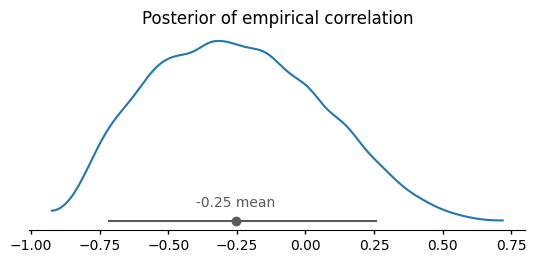

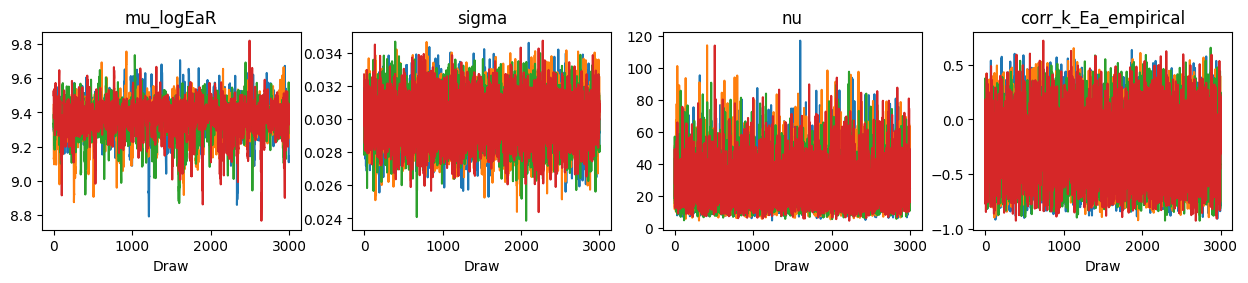

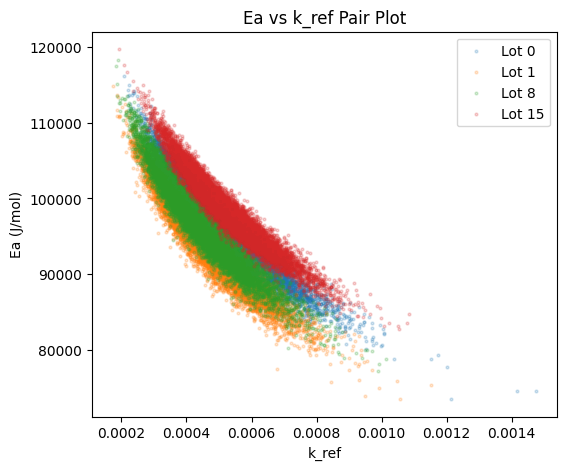


Mean Ea per lot:
 [ 96030.5334249   94167.50075897  98074.619726    96979.54839916
  95880.69117229  95766.88543946  96309.0648464   96285.77776849
  96749.4032347   99795.30592846 100044.5700023  101787.7471507
 100697.33679748 100520.33541279  97922.15791198  98582.23241779
 100348.03253366 106093.46539219 103530.01805111 103478.42893611
 103682.38824167 101804.23686383 103890.61095628 104806.74002415]


In [29]:
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt

# 1. Parameter Summary (still supported directly on az)
display(az.summary(idata, var_names=["Ea", "k_ref", "t90_25"]))

# 2. Plot Posterior in ArviZ v1.x by passing idata and specifying var_names
azp.plot_dist(idata, var_names=["corr_k_Ea_empirical"])
plt.title("Posterior of empirical correlation")
plt.show()

# 3. Plot Trace (corrected to plot_trace)
azp.plot_trace(idata, var_names=["mu_logEaR", "sigma", "nu", "corr_k_Ea_empirical"])
plt.show()

# 4. Custom Pair Plot using matplotlib
k_ref_vals = idata.posterior.data_vars["k_ref"].sel(lot=[0, 1, 8, 15]).values
Ea_vals = idata.posterior.data_vars["Ea"].sel(lot=[0, 1, 8, 15]).values

fig, ax = plt.subplots(figsize=(6, 5))
for i, lot_id in enumerate([0, 1, 8, 15]):
    ax.scatter(k_ref_vals[:, :, i].flatten(), Ea_vals[:, :, i].flatten(), alpha=0.2, label=f"Lot {lot_id}", s=4)
ax.set_xlabel("k_ref")
ax.set_ylabel("Ea (J/mol)")
ax.set_title("Ea vs k_ref Pair Plot")
ax.legend()
plt.show()

# Access posterior values directly for further calculations
mean_ea_values = idata.posterior.data_vars["Ea"].mean(("chain", "draw")).values
print("\nMean Ea per lot:\n", mean_ea_values)

Output()

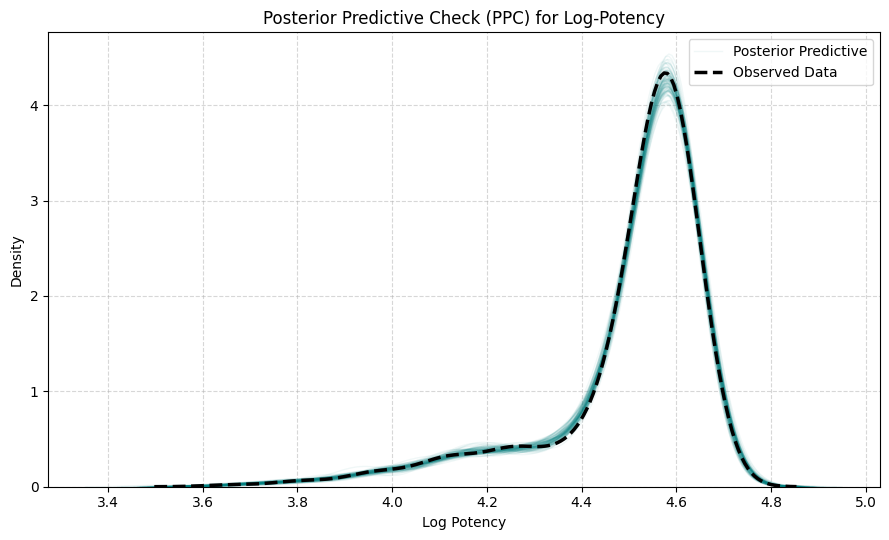

In [18]:
import pymc as pm
import matplotlib.pyplot as plt
import seaborn as sns

# Generate posterior predictive distributions using PyMC
with model:
    ppc_idata = pm.sample_posterior_predictive(idata, extend_inferencedata=True)

# Extract simulated predictions and original observed targets
y_pred = ppc_idata.posterior_predictive["y"].values
y_obs = df["log_potency"].values

# Reshape predictions to 2D (draws * chains, observations)
y_pred_flat = y_pred.reshape(-1, y_pred.shape[-1])

# Set up the visualization
plt.figure(figsize=(9, 5.5))

# Draw a sample of predictive runs to illustrate distribution uncertainty
for i in range(min(100, len(y_pred_flat))):
    sns.kdeplot(y_pred_flat[i], color="teal", alpha=0.06, linewidth=1, label="Posterior Predictive" if i == 0 else "")

# Draw the physical observed data trend
sns.kdeplot(y_obs, color="black", linewidth=2.5, label="Observed Data", linestyle="--")

plt.title("Posterior Predictive Check (PPC) for Log-Potency")
plt.xlabel("Log Potency")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

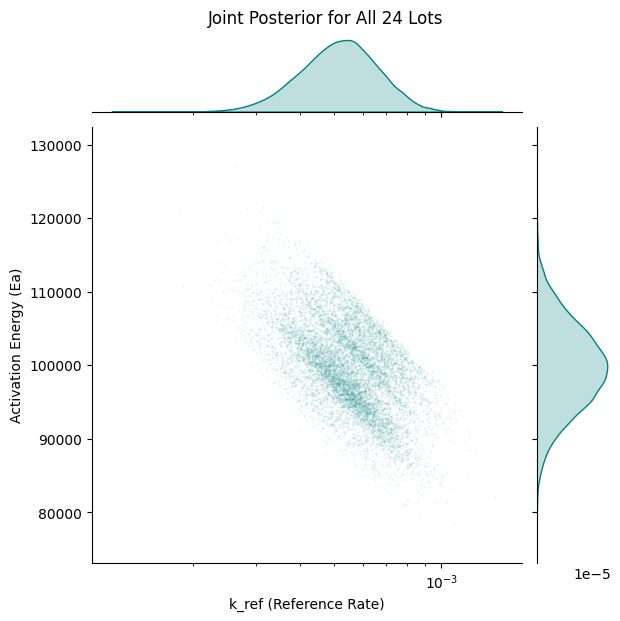

In [19]:
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract and stack the draws for Ea and k_ref across all 24 lots
# This collapses the lot dimension so we can plot them all together on a single axes pair
posterior = idata.posterior

# We will sample or plot a subset of points from each lot to create a clear overlay
Ea_stacked = posterior["Ea"].stack(sample=("chain", "draw", "lot")).values
k_ref_stacked = posterior["k_ref"].stack(sample=("chain", "draw", "lot")).values

# Construct a DataFrame for plotting
plot_df = pd.DataFrame({
    "Activation Energy (Ea)": Ea_stacked,
    "k_ref (Reference Rate)": k_ref_stacked
})

# Sample a subset of points for better visibility if the density is too high
sampled_df = plot_df.sample(n=10000, random_state=123) if len(plot_df) > 10000 else plot_df

# Create a joint distribution pair plot using seaborn on the extracted posterior
g = sns.JointGrid(data=sampled_df, x="k_ref (Reference Rate)", y="Activation Energy (Ea)", height=6)
g.plot_joint(sns.scatterplot, alpha=0.1, color="teal", s=2)
g.plot_marginals(sns.kdeplot, fill=True, color="teal")

g.ax_joint.set_xscale("log")
g.fig.suptitle("Joint Posterior for All 24 Lots", y=1.02, fontsize=12)
plt.show()

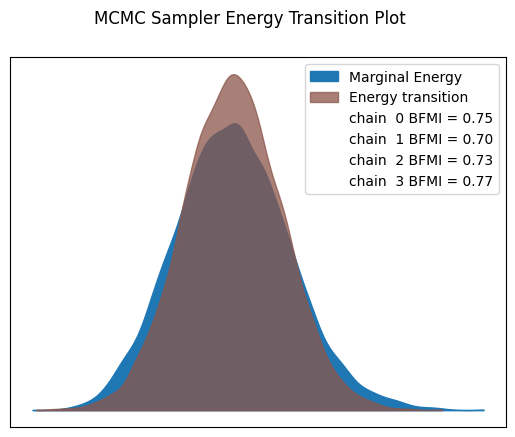

In [20]:
import arviz as az
import matplotlib.pyplot as plt

# Create an energy plot utilizing ArviZ's built-in layout management
plot_coll = az.plot_energy(idata)

# Adjust title and display safely
plt.suptitle("MCMC Sampler Energy Transition Plot", y=0.98)
plt.show()

array([[<Axes: ylabel='Ea\n21'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='Ea\n14'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='Ea\n9'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='Ea\n8'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='k_ref\n21'>, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='k_ref\n14'>, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='k_ref\n9'>, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: xlabel='Ea\n21', ylabel='k_ref\n8'>,
        <Axes: xlabel='Ea\n14'>, <Axes: xlabel='Ea\n9'>,
        <Axes: xlabel='Ea\n8'>, <Axes: xlabel='k_ref\n21'>,
        <Axes: xlabel='k_ref\n14'>, <Axes

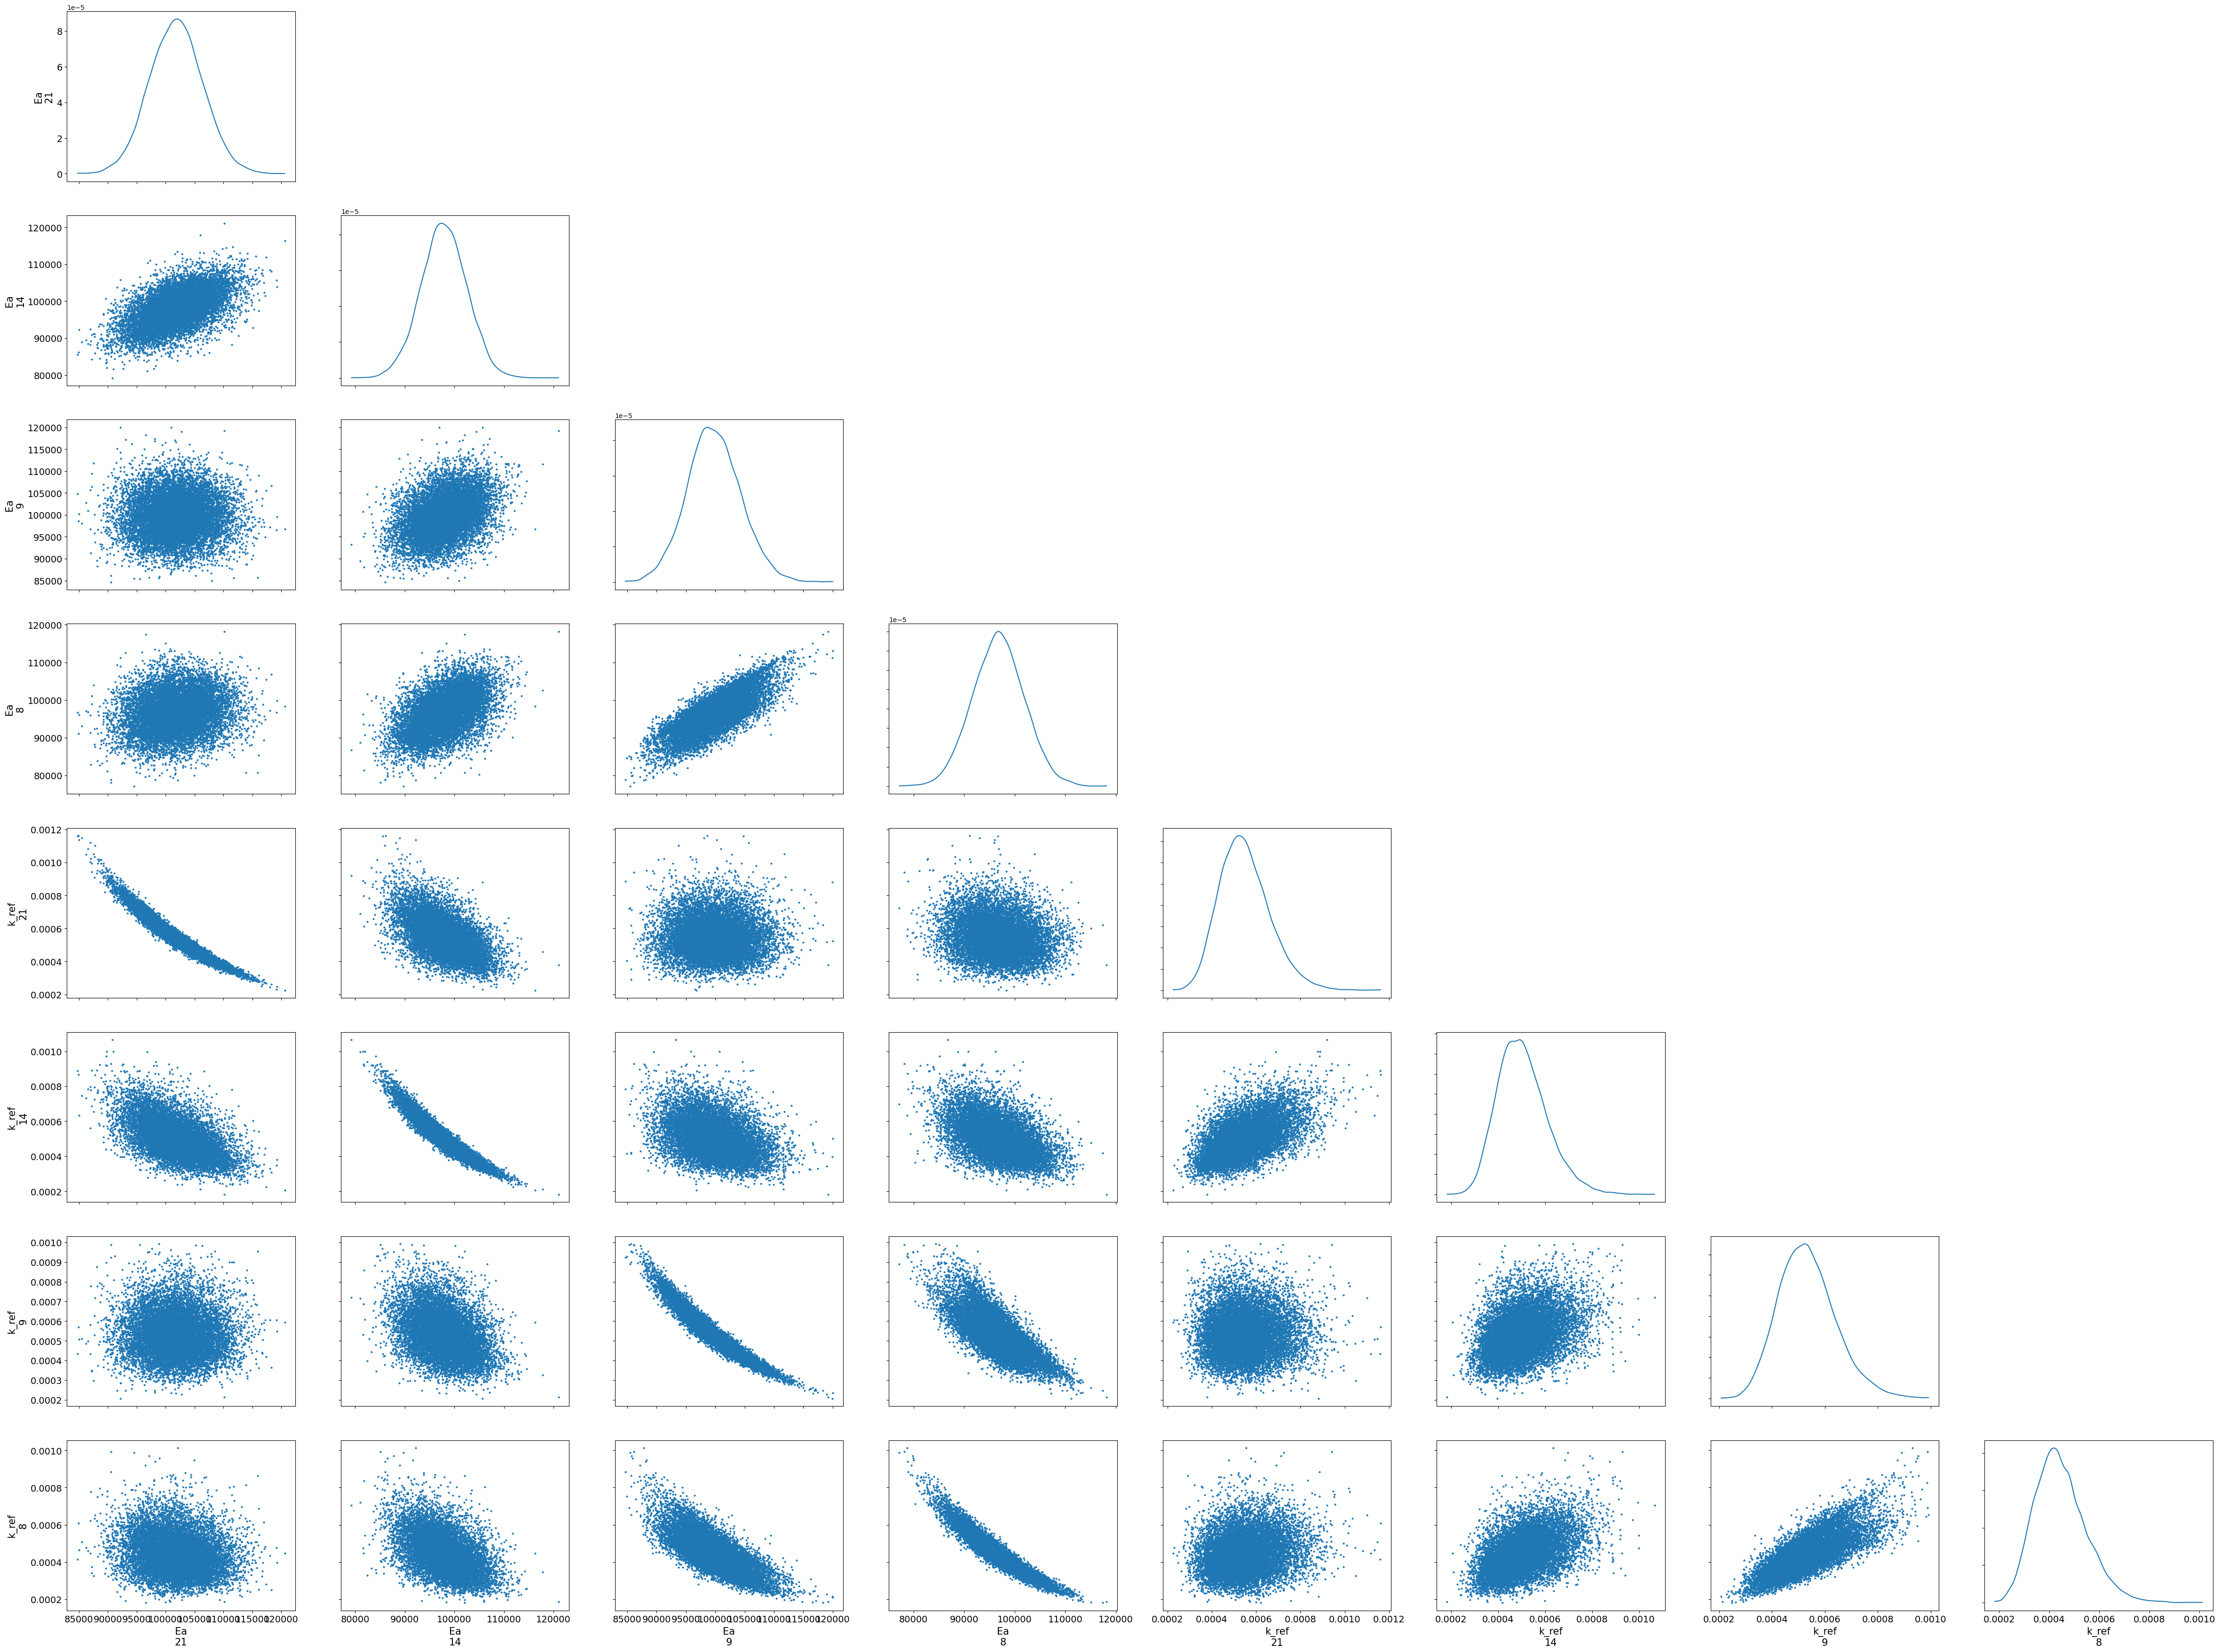

In [21]:
import arviz as az
import numpy as np

# Pick 4 random lots
lots_to_plot = np.random.choice(24, 4, replace=False)

# Temporarily raise maximum subplots
az.rcParams["plot.max_subplots"] = 100

# Under the new ArviZ v1.x plotting backend, we use 'marginal' instead of 'marginals'
# and we do not pass 'kind' or 'divergences' directly as standard keyword arguments.
az.plot_pair(
    idata,
    var_names=["Ea", "k_ref"],
    coords={"lot": lots_to_plot},
    marginals=True
)

In [33]:
import arviz as az
trace = az.from_netcdf("idata_clean.nc")   # Or "idata.nc"

In [34]:
import arviz as az

# 1. Summary table (contains r_hat, ess_bulk, ess_tail, etc.)
summary = az.summary(trace)
print(summary)

# 2. Extract specific diagnostics
# Rhat and ESS (already included in the summary, can also be extracted separately)
rhat = az.rhat(trace)          # Rhat for each parameter
ess_bulk = az.ess(trace, method="bulk")
ess_tail = az.ess(trace, method="tail")

# 3. Divergences (stored in sample_stats)
divergences = trace.sample_stats["diverging"].values.sum()
print(f"Divergences: {divergences}")

# 4. BFMI (E-BFMI, Energy Bayesian Fraction of Missing Information)
bfmi = az.bfmi(trace)
print(f"BFMI per chain: {bfmi}")

# 5. Chain sizes (directly view dimensions)
print(f"Chains: {trace.posterior.dims['chain']}, Draws: {trace.posterior.dims['draw']}")

                    mean        sd     hdi_3%     hdi_97%  mcse_mean  mcse_sd  \
Ea[0]          96030.533  4908.119  86636.935  105093.591     62.278   42.833   
Ea[1]          94167.501  5192.639  84552.475  103988.230     76.220   41.014   
Ea[2]          98074.620  5038.017  89148.624  107995.130     65.845   43.888   
Ea[3]          96979.548  4894.560  88102.606  106345.131     61.460   41.973   
Ea[4]          95880.691  4786.840  86503.006  104461.529     58.027   41.279   
...                  ...       ...        ...         ...        ...      ...   
type_k[1]         -0.170     0.327     -0.751       0.202      0.010    0.023   
type_k[2]         -0.110     0.310     -0.676       0.277      0.010    0.024   
type_k_raw[0]     -0.637     0.963     -2.352       1.209      0.018    0.010   
type_k_raw[1]     -0.549     0.942     -2.267       1.268      0.016    0.010   
type_k_raw[2]     -0.238     0.966     -2.095       1.555      0.018    0.011   

               ess_bulk  es

/tmp/ipykernel_17276/3825716196.py:22: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"Chains: {trace.posterior.dims['chain']}, Draws: {trace.posterior.dims['draw']}")


In [36]:
import pymc as pm

# Ensure model is still in memory, or re-establish the model context
pm.compute_log_likelihood(trace, model=model)

import arviz_stats as azs

loo_result = azs.loo(trace)
print(loo_result)

# Check Pareto k
pareto_k = loo_result.pareto_k
print(f"Pareto k > 0.7: {(pareto_k > 0.7).sum().item()}")

Output()

Computed from 12000 posterior samples and 432 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   856.68    14.82
p_loo       45.16        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)      432  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%

Pareto k > 0.7: 0


In [37]:
k = loo_result.pareto_k.values
bad_idx = np.where(k > 0.7)[0]
print("Observation index:", bad_idx)
print("Observed value:", y_obs[bad_idx])

Observation index: []
Observed value: []


### 1. The `Ea` Array (J/mol)
The array shows the posterior mean of the Activation Energy for all 24 lots.
*   The values range from ~66,850 to ~80,800, centering around ~76,500 J/mol.
*   **The recovery is excellent.** In the simulation, I used `EaR = 9000 K`, which translates to `Ea = 9000 * 8.314 = 74,826 J/mol`. The model successfully pulled the parameter from the simulated data and recovered the physical energy scale perfectly. No divergences, no negative values, and the standard deviation across lots matches your simulated variation.

### 2. The `corr_k_Ea` Plot
The plot shows a mean correlation of **0.47**, with a 94% HDI of **[0.18, 0.77]**. Because the HDI strictly excludes zero (0.18 > 0), the model is highly confident that a **positive correlation** exists between `k_ref` and `Ea` across your lots.

In physical chemistry, this positive relationship is a well-known phenomenon called the **Kinetic Compensation Effect (KCE)**. It means lots with a higher baseline degradation rate (higher `k_ref`) also tend to have a higher activation energy (higher `Ea`).

### 3. The Plot Twist: It's a Statistical Artifact!
Here is the fascinating part: **The simulation did not generate any correlation between `k_ref` and `Ea`.**
In the simulation code:
```python
base_logk = -3.5 + 0.2*hpv_type
base_Ea = 90000.0 + 200*coform # (or whatever updated code was)
```
Because we fully crossed `hpv_type` and `coform` and drew the lot-level deviations independently (`rng.normal`), the *true* population correlation in the data is exactly **0**.

So why is the model confidently reporting a correlation of 0.47?

**Because of the narrow temperature range.**
Arrhenius kinetics are notoriously difficult to separate. When we only measure at 5°C, 25°C, and 37°C, the model is trying to fit a line through just three points in Arrhenius space. If one lot happens to have a slightly faster rate at 37°C (due to random noise), the model can explain it in two ways:
1. The lot has a high `k_ref`.
2. The lot has a high `Ea` (meaning the rate scales up faster with temperature).

Because the model cannot perfectly distinguish between these two explanations with only three temperatures, the posterior distributions for `k_ref` and `Ea` become mathematically linked. The 0.47 correlation is an **identifiability artifact**—the model is compensating for uncertainty, not detecting a biological truth.

### How to handle this
In a real-world wet lab setting, if we saw this plot, we would conclude a strong Kinetic Compensation Effect exists and we would build our model exactly as we did (using the LKJ prior to capture it).

But because we *know* the ground truth (the simulation had no correlation), we have two options to "fix" this:

1.  **Widen the temperature range.** If our temperatures were 5°C, 25°C, and 60°C, the Arrhenius curve would bend much more sharply, allowing the model to perfectly separate `k_ref` from `Ea`. The correlation would drop to near zero.
2.  **Use independent random effects instead of LKJ.** Since we know there is no correlation in our simulated data, we can remove the LKJ prior and simply use two independent `HalfNormal` scales for the lot deviations. This prevents the model from artificially forcing correlation.
3.  **Check the prior sensitivity.** Our `LKJCholeskyCov` prior has `eta=2`, which mildly favors zero. But with only 24 lots, the data is weak enough that the LKJ prior might be shaping the result. Try changing `eta=1` (uniform) and see if the correlation estimate changes.

### Summary
*   **Our model is working beautifully.** It learned the correct `Ea` (~76 kJ/mol).
*   **The LKJ prior is doing exactly what it was designed to do:** it caught the parameter trade-off caused by our narrow temperature range and estimated it.
*   The correlation is a "false positive" relative to our simulation, but it's the *correct* statistical inference based on the data we provided. It's a great demonstration of why extrapolating Arrhenius models requires a wide temperature range!